# AI Crop Doctor — Milestone 2: Model Development, Evaluation & Optimization

## 1. Environment and configuration

In [20]:
import os, json, zipfile, random, warnings, gc, time
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import zipfile
import json

from sklearn.metrics import (classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    top_k_accuracy_score)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

# Update these paths if your Kaggle input dataset/zip names differ.
PREPROCESSING_ZIP = "/kaggle/input/your-dataset/Preprocessing.zip"
DATASET_ROOT = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"
OUTPUT_DIR = "/kaggle/working/AI_Crop_Doctor_M2"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = (128, 128)  # keep 128 for fair comparison with the supplied CNN
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS_SCRATCH = 12
EPOCHS_HEAD = 5
EPOCHS_FINE = 8

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load M1 manifest and verify leakage controls

In [21]:
BASE_PATH = "/kaggle/input/datasets/omarwalied2005/preprocessing/Preprocessing"

splits_path = os.path.join(BASE_PATH, "splits.csv")
class_mapping_path = os.path.join(BASE_PATH, "class_to_idx.json")
weights_path = os.path.join(BASE_PATH, "class_weights.csv")

manifest = pd.read_csv(splits_path)

with open(class_mapping_path, "r") as f:
    class_to_idx = json.load(f)

weights_df = pd.read_csv(weights_path)

print("Manifest loaded:", manifest.shape)
print("Number of classes:", len(class_to_idx))
print("\nSplit distribution:")
print(manifest["split"].value_counts())
print("\nColumns:", manifest.columns.tolist())

Manifest loaded: (87867, 18)
Number of classes: 38

Split distribution:
split
train    61541
test     13172
val      13154
Name: count, dtype: int64

Columns: ['image_id', 'path', 'relative_path', 'filename', 'class', 'label', 'group_id', 'group_size', 'sha256', 'split_original', 'fold', 'split', 'width', 'height', 'mode', 'format', 'cross_class_group', 'cross_original_split_group']


## 3. TensorFlow input pipeline

In [22]:
# Create DataFrames from the M1 group-aware splits
train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "val"].copy()
test_df = manifest[manifest["split"] == "test"].copy()

# Reset indexes
train_df.reset_index(drop=True, inplace=True)
val_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

# Verify
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nClasses:", len(class_to_idx))
print("\nSplit labels:")
print(manifest["split"].value_counts())

Training images: 61541
Validation images: 13154
Testing images: 13172

Classes: 38

Split labels:
split
train    61541
test     13172
val      13154
Name: count, dtype: int64


In [23]:
def decode_resize(path, label):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, method="bilinear")
    image = tf.cast(image, tf.float32)
    return image, tf.one_hot(label, depth=len(class_names))

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame.path.to_numpy(), frame.label.to_numpy().astype("int32")
    ))
    if training:
        ds = ds.shuffle(min(len(frame), 20000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, True)
val_ds = make_ds(val_df, False)
test_ds = make_ds(test_df, False)

## 4. Baseline 1 — majority-class predictor

In [24]:
majority_label = int(train_df.label.value_counts().idxmax())
y_val = val_df.label.to_numpy()
majority_pred = np.full_like(y_val, majority_label)
majority_accuracy = accuracy_score(y_val, majority_pred)
print("Majority class:", class_names[majority_label])
print("Validation accuracy:", round(majority_accuracy, 4))

Majority class: Soybean___healthy
Validation accuracy: 0.0284


## 5. Baseline 2 — Custom CNN trained on M1 splits

In [25]:
def build_custom_cnn():
    inputs = tf.keras.Input((*IMG_SIZE, 3))
    x = tf.keras.layers.Rescaling(1./255)(inputs)
    x = tf.keras.layers.RandomFlip("horizontal")(inputs)
    x = tf.keras.layers.RandomRotation(0.05)(x)
    x = tf.keras.layers.RandomZoom(0.10)(x)
    for filters in [32, 64, 128, 256]:
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Dropout(0.15)(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="CustomCNN_M1")

scratch_model = build_custom_cnn()
scratch_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "custom_cnn_best.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, "custom_cnn_history.csv"))
]
scratch_history = scratch_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_SCRATCH, callbacks=callbacks
)
scratch_model.save(os.path.join(OUTPUT_DIR, "custom_cnn_final.keras"))

Epoch 1/12


E0000 00:00:1793880816.675852      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CustomCNN_M1_1/dropout_1_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


1924/1924 ━━━━━━━━━━━━━━━━━━━━ 719s 368ms/step - accuracy: 0.6350 - loss: 1.3279 - val_accuracy: 0.4561 - val_loss: 2.0909
Epoch 2/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 213s 111ms/step - accuracy: 0.8270 - loss: 0.5811 - val_accuracy: 0.5833 - val_loss: 1.5454
Epoch 3/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 213s 111ms/step - accuracy: 0.8793 - loss: 0.3912 - val_accuracy: 0.6691 - val_loss: 1.3016
Epoch 4/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 213s 111ms/step - accuracy: 0.9092 - loss: 0.2968 - val_accuracy: 0.6530 - val_loss: 1.2719
Epoch 5/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 213s 111ms/step - accuracy: 0.9263 - loss: 0.2374 - val_accuracy: 0.7837 - val_loss: 0.7428
Epoch 6/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 213s 111ms/step - accuracy: 0.9376 - loss: 0.2003 - val_accuracy: 0.6259 - val_loss: 1.5714
Epoch 7/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 214s 111ms/step - accuracy: 0.9458 - loss: 0.1709 - val_accuracy: 0.6527 - val_loss: 1.5978
Epoch 8/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 214s 111ms/step - accuracy: 0.9

## 6. Transfer learning — MobileNetV3Large, two-stage fine-tuning

In [26]:
# MobileNetV3 includes its own input preprocessing by default when include_preprocessing=True.
# Our dataset loader outputs [0,1]; the application model handles preprocessing internally.
base = tf.keras.applications.MobileNetV3Large(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet",
    include_preprocessing=True
)
base.trainable = False

inputs = tf.keras.Input((*IMG_SIZE, 3))
x = base(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
transfer_model = tf.keras.Model(inputs, outputs, name="MobileNetV3Large_M1")

transfer_model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=["accuracy"]
)
head_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "mobilenetv3_head_best.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
]
head_history = transfer_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=head_callbacks
)

# Fine-tune only the upper part of the backbone; keep BatchNorm layers frozen.
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=["accuracy"]
)
fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "mobilenetv3_best.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, "mobilenetv3_finetune_history.csv"))
]
fine_history = transfer_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, callbacks=fine_callbacks
)
transfer_model.save(os.path.join(OUTPUT_DIR, "mobilenetv3_final.keras"))

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Epoch 1/5


E0000 00:00:1793883036.446712     161 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793883036.620246     161 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1921/1924 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5705 - loss: 1.8251

E0000 00:00:1793883081.326430     161 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793883081.495441     161 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1924/1924 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5707 - loss: 1.8243

... (2 outputs left out)

E0000 00:00:1793883290.508587     159 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793883290.666142     159 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1922/1924 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9511 - loss: 0.6424

E0000 00:00:1793883337.367133     160 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1924/1924 ━━━━━━━━━━━━━━━━━━━━ 79s 32ms/step - accuracy: 0.9573 - loss: 0.6190 - val_accuracy: 0.9708 - val_loss: 0.5600
Epoch 2/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 46s 24ms/step - accuracy: 0.9687 - loss: 0.5770 - val_accuracy: 0.9755 - val_loss: 0.5401
Epoch 3/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.9753 - loss: 0.5520 - val_accuracy: 0.9789 - val_loss: 0.5244
Epoch 4/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.9797 - loss: 0.5341 - val_accuracy: 0.9803 - val_loss: 0.5124
Epoch 5/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.9834 - loss: 0.5178 - val_accuracy: 0.9819 - val_loss: 0.5015
Epoch 6/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.9862 - loss: 0.5048 - val_accuracy: 0.9842 - val_loss: 0.4923
Epoch 7/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.9888 - loss: 0.4935 - val_accuracy: 0.9847 - val_loss: 0.4849
Epoch 8/8
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 47s 24ms/step - accuracy: 0.9908 - loss: 0.4828 - va

## 7. Imbalance ablation — effective-number weighted CNN

In [27]:
# Pull effective-number weights from the M1 export. Detect the appropriate class/weight columns.
print(weights_df.columns.tolist())

['class', 'train_images', 'inverse_frequency_weight', 'effective_number_weight']


In [28]:
# Map M1 class names to class indices. Adjust the column names below only if the printed schema differs.
class_col = next(c for c in weights_df.columns if c.lower() in ["class", "class_name", "label_name"])
weight_col = next(c for c in weights_df.columns if "effective" in c.lower() and "weight" in c.lower())
weight_map = dict(zip(weights_df[class_col], weights_df[weight_col]))
class_weight = {class_to_idx[name]: float(weight_map[name]) for name in class_names}
print("Class weights loaded:", len(class_weight))

Class weights loaded: 38


In [29]:
weighted_model = build_custom_cnn()
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
weighted_history = weighted_model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_SCRATCH,
    class_weight=class_weight,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            os.path.join(OUTPUT_DIR, "custom_cnn_effective_weighted_best.keras"),
            monitor="val_loss", save_best_only=True
        ),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    ]
)

Epoch 1/12


E0000 00:00:1793883690.977239      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CustomCNN_M1_1/dropout_7_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


1924/1924 ━━━━━━━━━━━━━━━━━━━━ 221s 113ms/step - accuracy: 0.6238 - loss: 1.3584 - val_accuracy: 0.4776 - val_loss: 1.9074
Epoch 2/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 216s 112ms/step - accuracy: 0.8133 - loss: 0.6230 - val_accuracy: 0.6029 - val_loss: 1.5542
Epoch 3/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 216s 112ms/step - accuracy: 0.8687 - loss: 0.4330 - val_accuracy: 0.6354 - val_loss: 1.3923
Epoch 4/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 216s 112ms/step - accuracy: 0.9019 - loss: 0.3160 - val_accuracy: 0.7378 - val_loss: 0.9348
Epoch 5/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 216s 112ms/step - accuracy: 0.9213 - loss: 0.2506 - val_accuracy: 0.7497 - val_loss: 0.8485
Epoch 6/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 215s 112ms/step - accuracy: 0.9326 - loss: 0.2103 - val_accuracy: 0.6715 - val_loss: 1.3118
Epoch 7/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 214s 111ms/step - accuracy: 0.9433 - loss: 0.1784 - val_accuracy: 0.7191 - val_loss: 1.1313
Epoch 8/12
1924/1924 ━━━━━━━━━━━━━━━━━━━━ 214s 111ms/step - accuracy: 0.9

## 7B. Classical baseline — HOG + colour histogram with Linear SVM


In [30]:

from PIL import Image
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.utils import resample

CLASSICAL_TRAIN_CAP = 12000  # reduce if RAM is limited
CLASSICAL_VAL_CAP = 6000

def classical_features(path, size=(64,64)):
    im = Image.open(path).convert("RGB").resize(size)
    arr = np.asarray(im, dtype=np.uint8)
    gray = np.asarray(im.convert("L"))
    h = hog(gray, orientations=9, pixels_per_cell=(8,8),
            cells_per_block=(2,2), block_norm="L2-Hys")
    hist_parts = []
    for ch in range(3):
        hist, _ = np.histogram(arr[:,:,ch], bins=16, range=(0,256), density=True)
        hist_parts.extend(hist)
    return np.concatenate([h, np.asarray(hist_parts, dtype=np.float32)])

ct = train_df.sample(min(CLASSICAL_TRAIN_CAP, len(train_df)), random_state=SEED)
cv = val_df.sample(min(CLASSICAL_VAL_CAP, len(val_df)), random_state=SEED)
X_ct = np.stack([classical_features(p) for p in ct.path])
X_cv = np.stack([classical_features(p) for p in cv.path])
svm = make_pipeline(StandardScaler(), LinearSVC(C=1.0, class_weight=None, random_state=SEED, dual="auto"))
svm.fit(X_ct, ct.label.to_numpy())
svm_val_pred = svm.predict(X_cv)
svm_val_metrics = {
    "accuracy": accuracy_score(cv.label, svm_val_pred),
    "macro_f1": precision_recall_fscore_support(
        cv.label, svm_val_pred, average="macro", zero_division=0
    )[2]
}
print("Classical HOG+RGB LinearSVC:", svm_val_metrics)


Classical HOG+RGB LinearSVC: {'accuracy': 0.5706666666666667, 'macro_f1': 0.571437525421934}


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## 8. Select candidate using validation macro-F1 (not test)

In [31]:
def predict_frame(model, ds):
    probs = model.predict(ds, verbose=1)
    pred = probs.argmax(axis=1)
    return probs, pred

def validation_macro_f1(model):
    probs, pred = predict_frame(model, val_ds)
    truth = val_df.label.to_numpy()
    p, r, f1, _ = precision_recall_fscore_support(
        truth, pred, labels=np.arange(len(class_names)), average="macro", zero_division=0
    )
    return {"accuracy": accuracy_score(truth,pred), "macro_precision":p,
            "macro_recall":r, "macro_f1":f1}

candidate_models = {
    "Custom CNN": scratch_model,
    "MobileNetV3Large": transfer_model,
    "Custom CNN effective-weighted": weighted_model
}
val_results = {name: validation_macro_f1(m) for name,m in candidate_models.items()}
val_results["HOG + RGB LinearSVC"] = svm_val_metrics
val_results_df = pd.DataFrame(val_results).T.sort_values("macro_f1", ascending=False)
display(val_results_df)
deep_model_rows = val_results_df.drop(index=["HOG + RGB LinearSVC"], errors="ignore")
best_name = deep_model_rows["macro_f1"].idxmax()
best_model = candidate_models[best_name]
print("Selected deep model on validation macro-F1:", best_name)
print("Classical baseline comparison:", val_results_df.loc["HOG + RGB LinearSVC"].to_dict())

412/412 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step
412/412 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step
412/412 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step


,accuracy,macro_precision,macro_recall,macro_f1
MobileNetV3Large,0.986772,0.986759,0.986551,0.986569
Custom CNN,0.783716,0.840902,0.782610,0.775653
Custom CNN effective-weighted,0.749734,0.824549,0.747428,0.740997
HOG + RGB LinearSVC,0.570667,NaN,NaN,0.571438


Selected deep model on validation macro-F1: MobileNetV3Large
Classical baseline comparison: {'accuracy': 0.5706666666666667, 'macro_precision': nan, 'macro_recall': nan, 'macro_f1': 0.571437525421934}


## 9. Final held-out test evaluation — run once after model selection

In [32]:
test_probs, test_pred = predict_frame(best_model, test_ds)
y_test = test_df.label.to_numpy()
test_accuracy = accuracy_score(y_test, test_pred)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_test, test_pred, average="macro", zero_division=0
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_test, test_pred, average="weighted", zero_division=0
)
print(classification_report(
    y_test, test_pred, labels=np.arange(len(class_names)),
    target_names=class_names, digits=4, zero_division=0
))

411/412 ━━━━━━━━━━━━━━━━━━━━ 0s 491ms/step

E0000 00:00:1793889180.344816     161 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793889180.518468     161 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


412/412 ━━━━━━━━━━━━━━━━━━━━ 208s 504ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9947    0.9921    0.9934       378
                                 Apple___Black_rot     1.0000    0.9947    0.9973       378
                          Apple___Cedar_apple_rust     0.9910    1.0000    0.9955       329
                                   Apple___healthy     0.9921    0.9973    0.9947       376
                               Blueberry___healthy     1.0000    1.0000    1.0000       335
          Cherry_(including_sour)___Powdery_mildew     1.0000    1.0000    1.0000       315
                 Cherry_(including_sour)___healthy     0.9886    1.0000    0.9943       347
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9800    0.9515    0.9655       309
                       Corn_(maize)___Common_rust_     0.9972    1.0000    0.9986       357
               Corn_(maize)___Nort

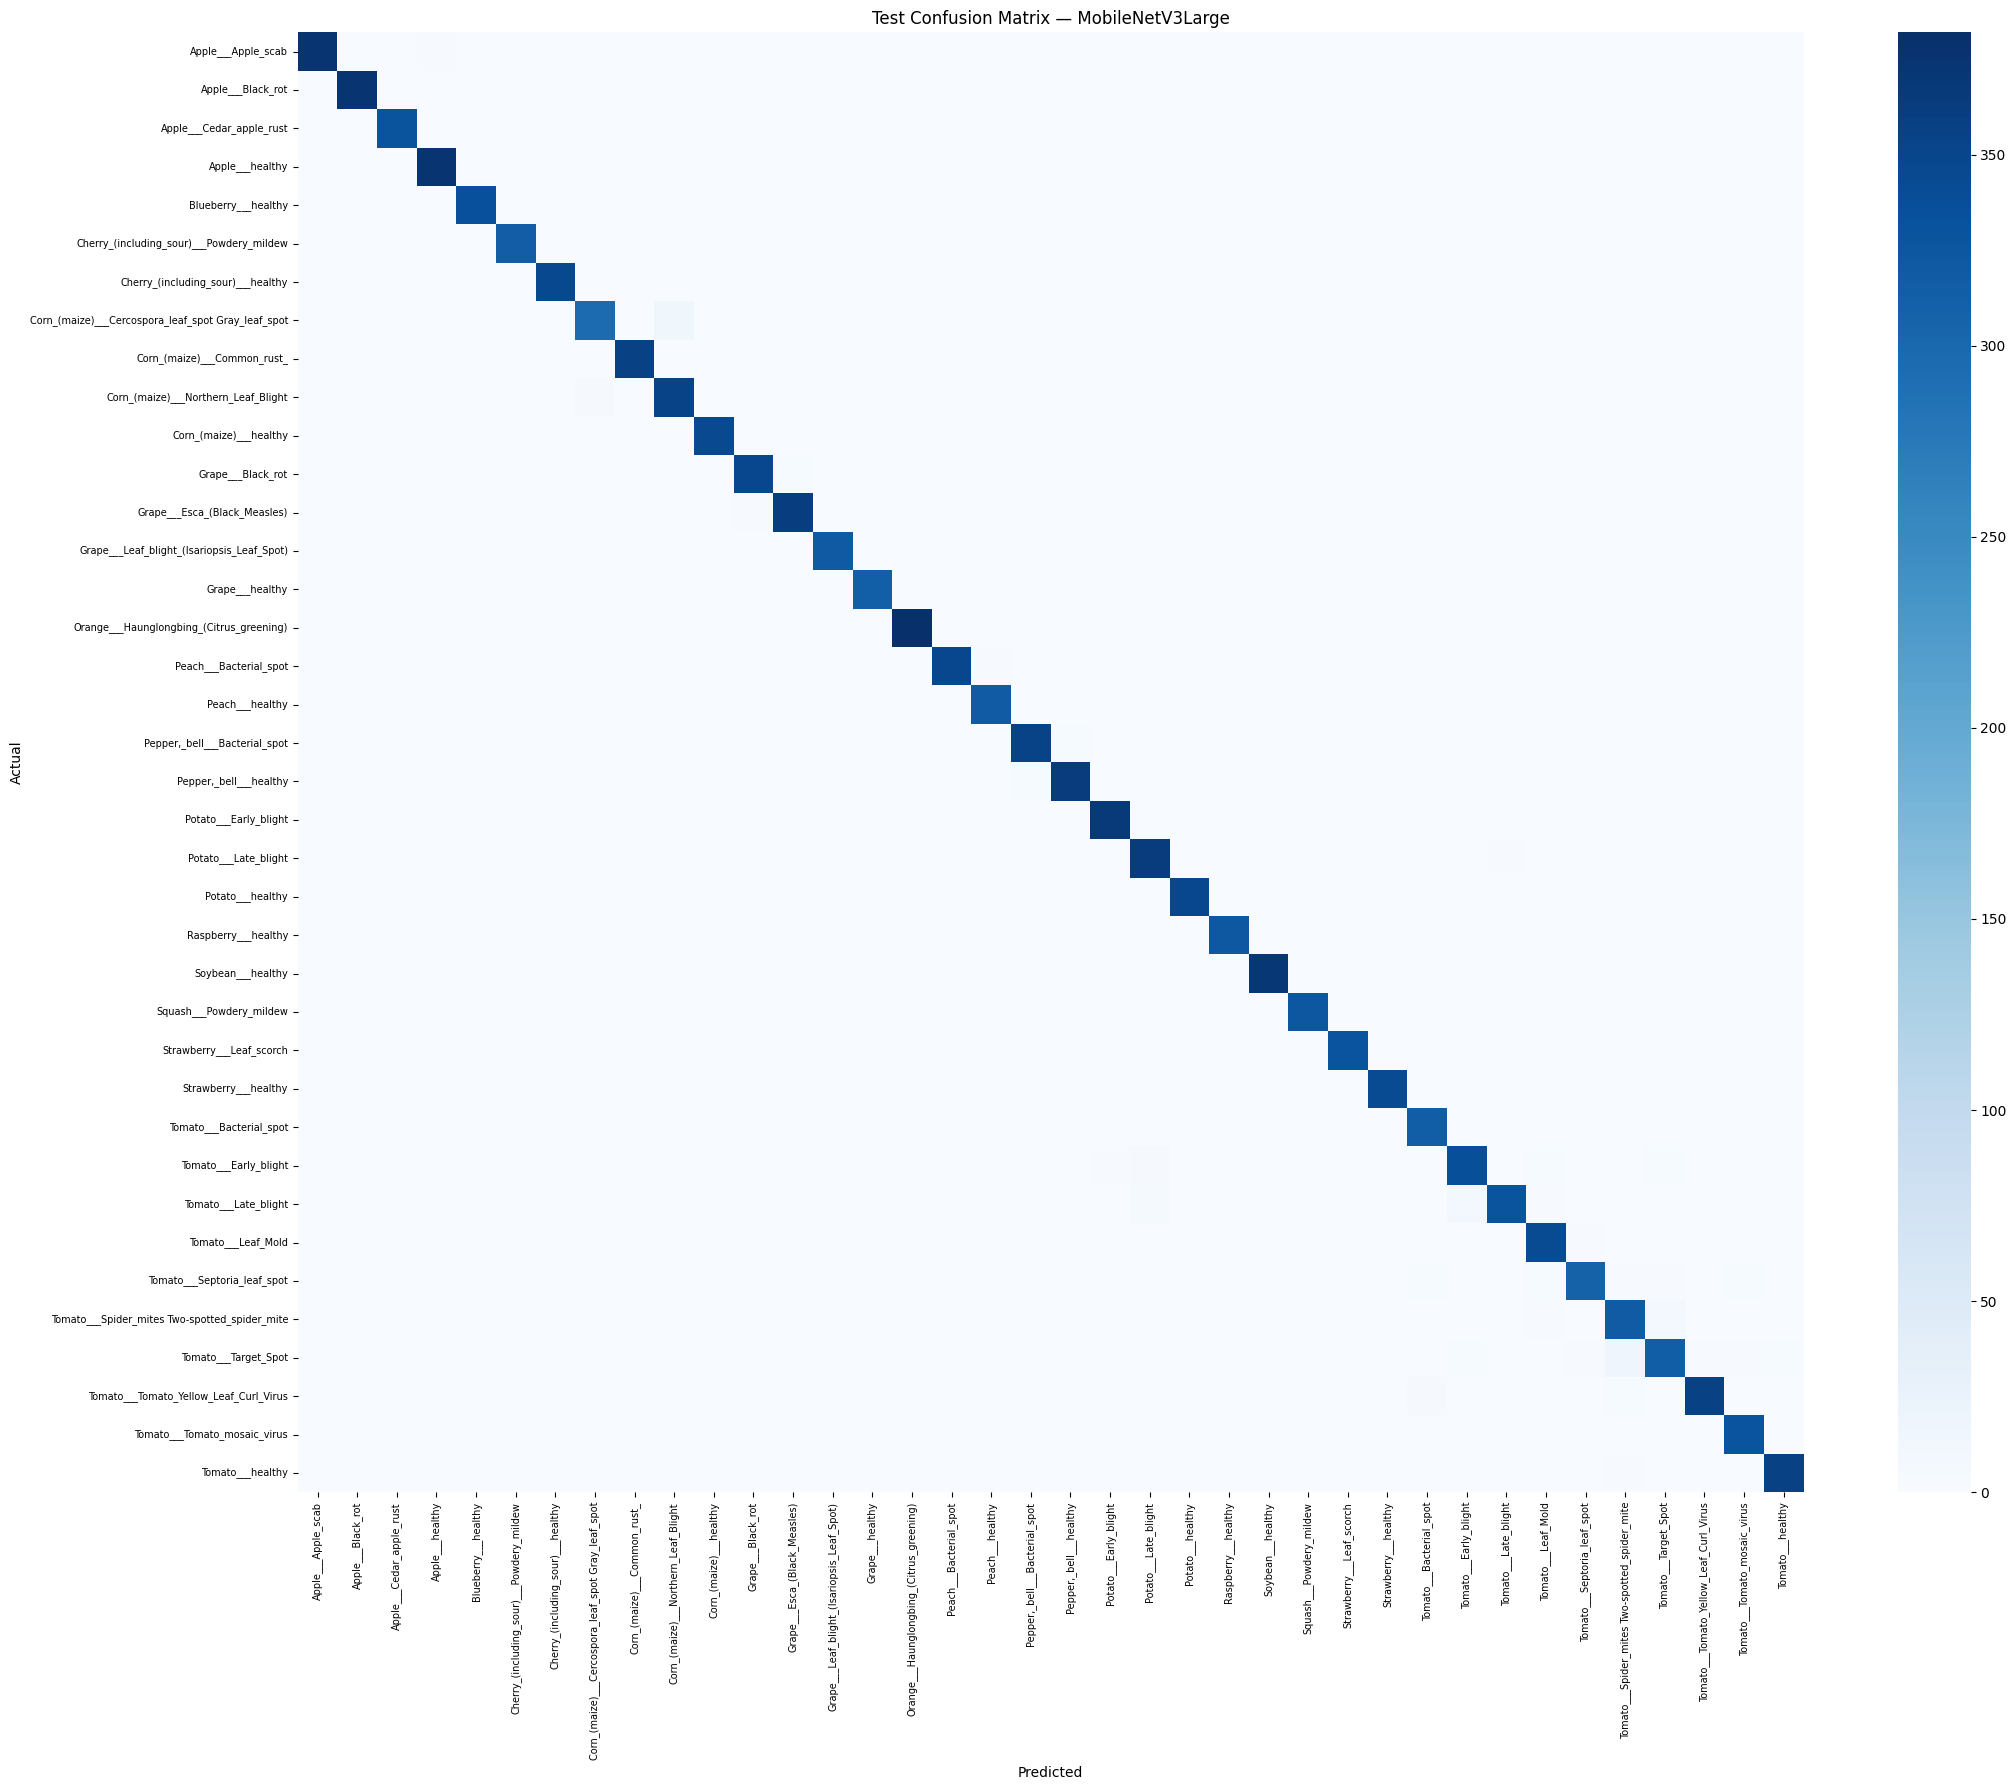

In [33]:
# One-vs-rest ROC-AUC. Requires one-hot labels matching the class order.
y_test_onehot = tf.keras.utils.to_categorical(y_test, num_classes=len(class_names))
try:
    macro_ovr_auc = roc_auc_score(y_test_onehot, test_probs, average="macro", multi_class="ovr")
except ValueError as e:
    macro_ovr_auc = None
    print("ROC-AUC unavailable:", e)

cm = confusion_matrix(y_test, test_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(22,18))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Test Confusion Matrix — {best_name}")
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=7); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,"test_confusion_matrix.png"), dpi=180)
plt.show()

per_class = classification_report(
    y_test, test_pred, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0
)
per_class_df = pd.DataFrame(per_class).T
per_class_df.to_csv(os.path.join(OUTPUT_DIR,"test_classification_report.csv"))

## 10. 95% bootstrap confidence intervals

In [34]:
# Bootstrap the held-out test predictions (paired resampling of examples).
rng = np.random.default_rng(SEED)
n = len(y_test)
boot_acc, boot_f1 = [], []
for _ in range(1000):
    ix = rng.integers(0, n, n)
    boot_acc.append(accuracy_score(y_test[ix], test_pred[ix]))
    _, _, f, _ = precision_recall_fscore_support(
        y_test[ix], test_pred[ix], average="macro", zero_division=0
    )
    boot_f1.append(f)
ci = {
    "accuracy_95ci": np.percentile(boot_acc,[2.5,97.5]).tolist(),
    "macro_f1_95ci": np.percentile(boot_f1,[2.5,97.5]).tolist()
}
ci

{'accuracy_95ci': [0.9839811721834194, 0.9880048587913757],
 'macro_f1_95ci': [0.9839553625917293, 0.9878827206551677]}

## 11. Per-crop metrics and final M2 report export

In [35]:
# Crop name is the part before the first triple underscore in the class label.
crop_for_label = {i: name.split("___",1)[0] for i,name in enumerate(class_names)}
crop_rows = []
for crop in sorted(set(crop_for_label.values())):
    ids = [i for i in range(len(class_names)) if crop_for_label[i] == crop]
    mask = np.isin(y_test, ids)
    crop_rows.append({
        "crop": crop,
        "support": int(mask.sum()),
        "accuracy": accuracy_score(y_test[mask], test_pred[mask]) if mask.any() else np.nan,
        "macro_f1": precision_recall_fscore_support(
            y_test[mask], test_pred[mask], labels=ids, average="macro", zero_division=0
        )[2] if mask.any() else np.nan
    })
crop_df = pd.DataFrame(crop_rows)
crop_df.to_csv(os.path.join(OUTPUT_DIR,"test_per_crop_metrics.csv"), index=False)

final_report = {
    "milestone": "M2",
    "dataset": "New Plant Diseases Dataset",
    "split_source": "M1 Preprocessing.zip / splits.csv",
    "selected_model": best_name,
    "validation_model_comparison": val_results,
    "test_metrics": {
        "accuracy": float(test_accuracy),
        "macro_precision": float(macro_p), "macro_recall": float(macro_r),
        "macro_f1": float(macro_f1), "weighted_precision": float(weighted_p),
        "weighted_recall": float(weighted_r), "weighted_f1": float(weighted_f1),
        "macro_ovr_roc_auc": None if macro_ovr_auc is None else float(macro_ovr_auc),
        **ci
    },
    "test_samples": int(n), "class_count": len(class_names),
    "notes": "Test partition used only after validation-based selection."
}
with open(os.path.join(OUTPUT_DIR,"m2_final_report.json"),"w") as f:
    json.dump(final_report,f,indent=2)
val_results_df.to_csv(os.path.join(OUTPUT_DIR,"validation_model_comparison.csv"))
print(json.dumps(final_report, indent=2))

{
  "milestone": "M2",
  "dataset": "New Plant Diseases Dataset",
  "split_source": "M1 Preprocessing.zip / splits.csv",
  "selected_model": "MobileNetV3Large",
  "validation_model_comparison": {
    "Custom CNN": {
      "accuracy": 0.7837159799300593,
      "macro_precision": 0.8409024134938788,
      "macro_recall": 0.7826096097553631,
      "macro_f1": 0.7756526214218374
    },
    "MobileNetV3Large": {
      "accuracy": 0.9867720845370229,
      "macro_precision": 0.9867586794622408,
      "macro_recall": 0.9865513924444154,
      "macro_f1": 0.9865687505150498
    },
    "Custom CNN effective-weighted": {
      "accuracy": 0.7497339212406873,
      "macro_precision": 0.8245485329391249,
      "macro_recall": 0.7474275431633286,
      "macro_f1": 0.7409968433985549
    },
    "HOG + RGB LinearSVC": {
      "accuracy": 0.5706666666666667,
      "macro_f1": 0.571437525421934
    }
  },
  "test_metrics": {
    "accuracy": 0.9860309747950198,
    "macro_precision": 0.9860494944713902,